In [3]:
# Load the model outputs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

segments = pd.read_csv("KMeans_Customer_Segments.csv")
transactions = pd.read_csv("Nassau Candy Distributor.csv")

print("Customer records:", len(segments))
print("Unique customers:", segments["Customer ID"].nunique())
print("Clusters:", sorted(segments["Cluster"].unique()))

display(segments.head())

Customer records: 5044
Unique customers: 5044
Clusters: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


,Customer ID,Total_Sales,Total_Profit,Total_Units,Order_Count,Transaction_Count,Product_Count,Average_Sales_Per_Order,Average_Units_Per_Order,Gross_Profit_Margin,Preferred_Division,Main_Region,Preferred_Ship_Mode,Cluster
0,100006,11.25,7.35,3,1,1,1,11.250000,3.0,65.333333,Chocolate,Atlantic,Standard Class,0
1,100013,18.00,12.50,5,1,3,1,18.000000,5.0,69.444444,Chocolate,Pacific,Standard Class,0
2,100041,21.25,14.31,6,3,3,3,7.083333,2.0,67.341176,Chocolate,Interior,Standard Class,3
3,100048,36.80,24.08,11,2,3,2,18.400000,5.5,65.434783,Chocolate,Atlantic,Standard Class,3
4,100055,18.30,12.40,5,2,2,2,9.150000,2.5,67.759563,Chocolate,Atlantic,Standard Class,0


In [4]:
# Generate the final customer profiles
profile = (
    segments.groupby("Cluster")
    .agg(
        Customer_Count=("Customer ID", "nunique"),
        Total_Sales=("Total_Sales", "sum"),
        Average_Sales=("Total_Sales", "mean"),
        Median_Sales=("Total_Sales", "median"),
        Average_Profit=("Total_Profit", "mean"),
        Average_Orders=("Order_Count", "mean"),
        Average_Units=("Total_Units", "mean"),
        Average_Products=("Product_Count", "mean")
    )
    .reset_index()
)

profile["Customer_Percentage"] = (
    profile["Customer_Count"] / len(segments) * 100
)

profile["Sales_Contribution_Percentage"] = (
    profile["Total_Sales"] / segments["Total_Sales"].sum() * 100
)

display(profile.round(2))

profile.to_csv("Final_Customer_Segment_Profiles.csv", index=False)

,Cluster,Customer_Count,Total_Sales,Average_Sales,Median_Sales,Average_Profit,Average_Orders,Average_Units,Average_Products,Customer_Percentage,Sales_Contribution_Percentage
0,0,2413,26463.41,10.97,10.80,7.32,1.12,3.15,1.12,47.84,18.66
1,1,339,34382.51,101.42,87.90,65.19,3.77,24.88,3.53,6.72,24.25
2,2,896,31428.01,35.08,28.80,23.18,1.23,9.56,1.22,17.76,22.17
3,3,1396,49509.70,35.47,33.38,23.57,2.48,10.07,2.46,27.68,34.92


,Total_Sales,Total_Profit,Order_Count,Total_Units,Product_Count
Cluster,,,,,
0,0.39,0.40,0.66,0.41,0.67
1,3.61,3.52,2.22,3.25,2.11
2,1.25,1.25,0.73,1.25,0.73
3,1.26,1.27,1.46,1.31,1.47


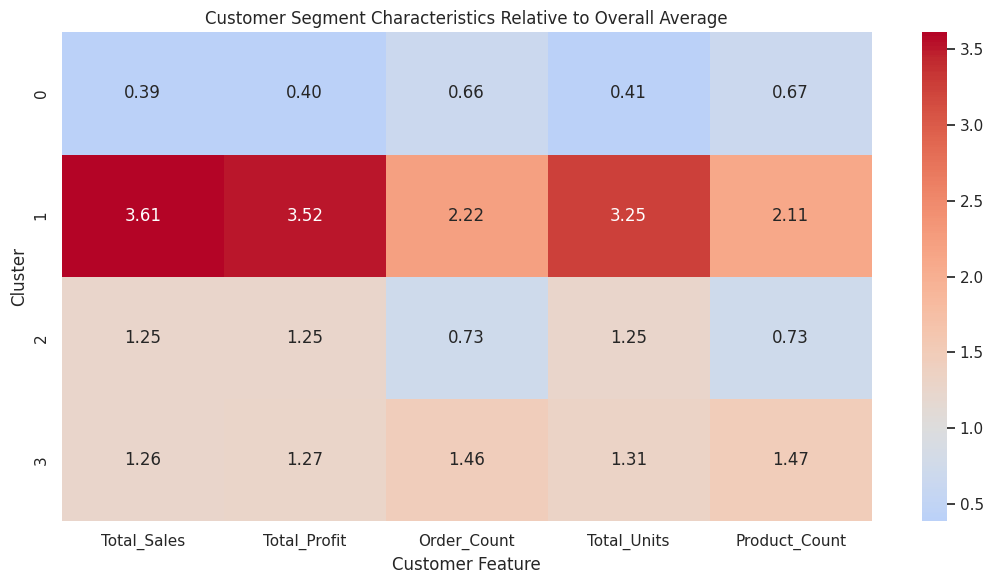

In [5]:
# Identify the most important segment characteristics
comparison_features = [
    "Total_Sales",
    "Total_Profit",
    "Order_Count",
    "Total_Units",
    "Product_Count"
]

cluster_means = segments.groupby("Cluster")[
    comparison_features
].mean()

# Compare each cluster's average with the overall average
relative_profile = (
    cluster_means / segments[comparison_features].mean()
)

display(relative_profile.round(2))

plt.figure(figsize=(11, 6))

sns.heatmap(
    relative_profile,
    annot=True,
    cmap="coolwarm",
    center=1,
    fmt=".2f"
)

plt.title("Customer Segment Characteristics Relative to Overall Average")
plt.xlabel("Customer Feature")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

In [6]:
# Analyze customer preferences by segment
categorical_features = [
    "Preferred_Division",
    "Main_Region",
    "Preferred_Ship_Mode"
]

for column in categorical_features:
    if column in segments.columns:
        print(f"\nDistribution of {column} by cluster:")

        distribution = pd.crosstab(
            segments["Cluster"],
            segments[column],
            normalize="index"
        ) * 100

        display(distribution.round(2))


Distribution of Preferred_Division by cluster:


Preferred_Division,Chocolate,Other,Sugar
Cluster,,,
0,97.22,2.24,0.54
1,99.12,0.88,0.00
2,97.10,2.90,0.00
3,99.93,0.07,0.00



Distribution of Main_Region by cluster:


Main_Region,Atlantic,Gulf,Interior,Pacific
Cluster,,,,
0,28.22,16.29,23.41,32.08
1,30.09,15.63,20.06,34.22
2,28.68,16.74,22.66,31.92
3,28.30,16.19,24.28,31.23



Distribution of Preferred_Ship_Mode by cluster:


Preferred_Ship_Mode,First Class,Same Day,Second Class,Standard Class
Cluster,,,,
0,15.83,5.55,18.81,59.80
1,12.98,3.24,20.35,63.42
2,15.74,5.47,19.42,59.38
3,15.76,5.01,19.27,59.96


In [7]:
# Export the interpreted results
# Save the assigned customer segments
segments.to_csv(
    "Final_Interpreted_Customer_Segments.csv",
    index=False
)

# Save the segment-level summary
profile.to_csv(
    "Final_Customer_Segment_Profiles.csv",
    index=False
)

print("Step 8 completed successfully!")
print("Files saved:")
print("1. Final_Interpreted_Customer_Segments.csv")
print("2. Final_Customer_Segment_Profiles.csv")

Step 8 completed successfully!
Files saved:
1. Final_Interpreted_Customer_Segments.csv
2. Final_Customer_Segment_Profiles.csv
